# 10 · EV fleet scheduling (V2G) with a quantum kernel
### استخدام الطاقة · Use — رحلة الكم من مصدر الطاقة إلى الاستدامة · Quantum Journey from Energy Source to Sustainability
*Quantum Computing Challenge 2026, Riyadh · Team 10 · Prepared by Ahmed Elghadban, Quantumy*<br><sub>Reviewed by Ola Tarig</sub>

| | |
|---|---|
| Use case | Decide which plugged-in electric cars should sell power back to the grid now (vehicle-to-grid) |
| Algorithm | Quantum kernel classifier (FidelityStatevectorKernel + QSVC) |
| Toy size | 4 qubits, runs in under 3 min on a laptop |
| Day 1 | read sections 0–2 |
| Day 2 | sections 3–6, build, pitch |

In [ ]:
# Setup: run me first. On Colab this clones the repo and installs the pinned packages (about 1 minute).
import sys, os, subprocess
if "google.colab" in sys.modules and not os.path.exists("Quantum-Computing-Challenge"):
    subprocess.run(["git", "clone", "-q", "https://github.com/QTACInstitute/Quantum-Computing-Challenge.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "Quantum-Computing-Challenge/requirements.txt"], check=True)
ROOT = "Quantum-Computing-Challenge" if os.path.exists("Quantum-Computing-Challenge/qff") else ".."
sys.path.insert(0, ROOT)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt
import qff
SEED = qff.SEED            # 2026
DATA = os.path.join(ROOT, "data")

## 0 · The journey so far — رحلة الكم
**«من المصدر إلى استخدام الطاقة»** · From the wellspring to the lamp

Before you switch on a lamp tonight, energy will have made one journey. It is found, it is moved, it is stored, and then it is used. Ten teams follow that journey today. Each team owns one moment of it, and each moment has a problem that is hard for ordinary computers at full scale.

1. **المصدر · Source.** Find the energy and decide where to harvest it: read the rock under the ground, place the turbines in the wind.
2. **الطريق · Move.** Get it across the country: watch the grid, route the ships, decide which power stations run.
3. **المخزن · Store.** Keep it for later, and keep carbon out of the air: batteries, hydrogen, capture materials. This is chemistry.
4. **استخدام الطاقة · Use.** Spend it well: make fresh water, charge and discharge a fleet of cars.

Your notebook is one chapter. The cell below lights your stop and lists all ten chapters so you can see who comes before and after you. When you pitch, start by saying where in the journey you are.

One rule for the whole challenge: **be honest about what is real.** As of November 2026 nobody has shown a quantum computer beating the best classical method on any of these ten problems. Your job is to explain the problem, show the idea on a small example, and say clearly what the small example does and does not prove.

In [ ]:
from qff.day import show_day
show_day(stop=4, challenge=10)

## 1 · This stop — هذه المحطة

**The problem.** Thousands of electric cars sit plugged in for hours. Each one can charge now, wait, or even **sell power back to the grid** (vehicle-to-grid, V2G) when the grid is stretched and the price is high, as long as it still leaves with enough charge. Deciding, car by car and hour by hour, who should do what is a big scheduling problem. A good optimiser can solve it, but slowly; a **learned model** can imitate the optimiser's decisions in a fraction of a second. Our question: can a model that uses a *quantum kernel* learn the rule "should this car discharge to the grid now?"

**Who faces it.** A utility or fleet operator with many plug-in vehicles (a depot, a car park, a charging network) and a grid operator who wants the flexibility.

<div style="border:1px solid rgba(208,38,112,0.35);border-left:6px solid #D02670;background:rgba(208,38,112,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#D02670;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🌍 Real world · في الواقع</span>

**What is real today.** The WEF/Aramco paper (Case 14, p. 28) describes E.ON and IBM scheduling a vehicle-to-grid fleet with a kernel-based learned model trained on approximate dynamic programming, plus quantum-kernel experiments with error mitigation, reporting performance "close to classical baselines". That is the honest state: quantum kernels have been tried on this kind of problem and come out about level with classical ones, not ahead.

</div>

**Why a quantum computer might help.** A quantum kernel measures how similar two situations are by comparing the quantum states a circuit makes from them. The hope is that some circuits make states whose similarity is hard to compute classically yet useful for classifying. What is still missing: no one has shown such a circuit that is useful *and* beats a classical kernel on real data.

| Paper's method | Our teaching route |
|---|---|
| Kernel-based learned model trained on approximate dynamic programming, plus quantum-kernel experiments with error mitigation (Case 14, p. 28) | A quantum-kernel support vector machine (Qiskit `FidelityStatevectorKernel` and `QSVC`) on 80 synthetic cars, 4 qubits |

## 2 · Made small — المسألة مصغَّرة

The data is a small synthetic fleet: **80 cars**, one row each, made by `tools/generate_v2g_data.py` (read it, it is short). Four numbers describe a car's situation, each scaled to run between 0 and 1 or close to it:

| column | meaning |
|---|---|
| `soc` | state of charge now (how full the battery is) |
| `hours_norm` | hours until the car leaves, divided by 12 |
| `price` | electricity price now, normalised |
| `load` | local grid load now, normalised |

and the label `discharge` is 1 if the car should sell power to the grid now, 0 if not. **This label comes from a simple rule written by us** (the car has spare charging time, and price and load are both on the high side). It stands in for the decisions of a real optimiser; it is *not* real fleet data. Four features means **4 qubits**: one qubit per feature.

We keep 60 cars for training and hide 20 for testing, so the test measures how well the model handles cars it has not seen.

In [ ]:
QUBITS = 4                       # one qubit per feature; the test runner reads this
import pandas as pd
from sklearn.model_selection import train_test_split

fleet = pd.read_csv(os.path.join(DATA, "v2g_fleet.csv"))
FEATURES = ["soc", "hours_norm", "price", "load"]
X = fleet[FEATURES].to_numpy()
y = fleet["discharge"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7, stratify=y)
print(f"{len(fleet)} cars | discharge rate {y.mean():.0%} | train {X_train.shape}, test {X_test.shape}")
fleet.head()

**Classical baseline first.** Before any quantum circuit, see what ordinary machine learning does. A **support vector machine** (SVM) draws the best dividing line between "discharge" and "do not discharge" cars. The first guess to beat is the laziest one: always say "do not discharge". The next is a straight-line SVM. Your task T1 adds the stronger classical model, an SVM with an **RBF kernel** (it can draw curved boundaries; the next section explains what a kernel is).

In [ ]:
# Classical baseline 1: the laziest guess, and a straight-line SVM.
from sklearn.svm import SVC

acc_majority = float(np.mean(y_test == 0))                    # always answer "do not discharge"
linear = SVC(kernel="linear", C=10).fit(X_train, y_train)
acc_linear = linear.score(X_test, y_test)
print(f"always say no: {acc_majority:.2f} | straight-line SVM: train {linear.score(X_train, y_train):.2f}, test {acc_linear:.2f}")

### 🧰 Toolbox: how the calls you will need are written · صندوق الأدوات

No internet? No problem. The cell under this table runs each call once on a **small toy that has nothing to do with the task**, so you can see the exact spelling, the order of the arguments, and what comes back. Run it, read the printed lines, and come back to it whenever a hint says "a method of ...". *What* to build, and with *which numbers*, is your job.

| To do | How it is written | What you get |
|---|---|---|
| the exact-simulation sampler | `from qiskit.primitives import StatevectorSampler` | `StatevectorSampler(seed=1, default_shots=4096)` |
| run a circuit | `job = sampler.run([qc])` | then `job.result()[0].data.meas.get_counts()` gives a dictionary like `{'0000': 3900, ...}` |
| measure every qubit | `qc.measure_all()` | adds a classical register named `meas` |
| the undo of a circuit | `qc.inverse()` | a new circuit that reverses `qc` |
| one circuit after another | `a.compose(b)` | a **new** circuit: `a` followed by `b` |
| bind a car's numbers | `fm.assign_parameters(x)` | a **new** circuit with one car's numbers filled in (the original `fm` is unchanged) |
| the quantum classifier | `from qiskit_machine_learning.algorithms import QSVC` | `QSVC(quantum_kernel=qk, C=10).fit(X, y)`, then `.score(X_test, y_test)` |
| share of a count | `counts.get("0000", 0) / shots` | 0 if the key never appeared |

In [ ]:
# Toolbox for 10, on toys (not the EV fleet).
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

bell = QuantumCircuit(2); bell.h(0); bell.cx(0, 1)
undo = bell.compose(bell.inverse())                        # a circuit followed by its own undo gives back |00>
undo.measure_all()                                         # adds a classical register named "meas"
counts_toy = StatevectorSampler(seed=1, default_shots=2000).run([undo]).result()[0].data.meas.get_counts()
print("counts:", counts_toy, "| share of '00':", counts_toy.get("00", 0) / 2000)
assert counts_toy == {"00": 2000}

toy_X = np.array([[0.1, 0.2], [0.2, 0.1], [0.8, 0.9], [0.9, 0.8]])
toy_y = np.array([0, 0, 1, 1])
toy_clf = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=zz_feature_map(2, reps=1)), C=10).fit(toy_X, toy_y)
print("QSVC accuracy on its own 4 training points:", toy_clf.score(toy_X, toy_y))
print("OK: toolbox 10 ran.")

### T1 · Warm-up: the classical RBF baseline · التمرين ١

**What you are about to build, and why.** Before any quantum circuit we need the classical model to beat. In T1 you train a support vector machine with an **RBF kernel**, the standard classical choice, on the 60 training cars and measure its accuracy on the 20 hidden test cars. Everything quantum later is judged against this number. (Section 3 explains what a kernel is and why the RBF one works; for now think of it as "a way of saying how alike two cars are".)

**The formula behind it.** The RBF kernel scores the similarity of two cars $a$ and $b$ by their distance in feature space, with a width $\gamma$ ("gamma"):

$$K_{\text{RBF}}(a,b)=e^{-\gamma\,\lVert a-b\rVert^2}\ \in(0,1] \tag{R}$$

Identical cars score 1; the further apart, the closer to 0. By hand: two cars at squared distance $0.25$ with $\gamma=1$ score $e^{-0.25}=0.78$. The SVM learns from the table of all such scores (section 3.1).

**Stuck? Open the hints one at a time, and try again after each. · تلميحات**

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 1 · a nudge · تلميح ١</summary>

You are using scikit-learn, which you have seen in the straight-line SVM cell just above. What do you change to get the RBF kernel instead of the linear one? What does `.score` return? If the training accuracy comes out at 1.00 and the test accuracy is lower, what does that tell you about the model?

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 2 · the structure · تلميح ٢</summary>

Steps: create and train the model (the support-vector classifier `SVC`, with the RBF kernel and C = 10) on the unscaled training features; compute its accuracy on the training set and on the test set; print both. Two details: `C` is a setting you pass when you create the model (a larger C makes it try harder to get every training car right), and in T1 the features stay *unscaled*, so do not use the scaler from section 3. The model's `.score(X, y)` method returns the share of cars it labels correctly, so you call it once with the training cars and once with the test cars.

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 3 · nearly there · تلميح ٣</summary>

```python
rbf = ______               # the trained RBF-kernel SVM
acc_rbf_train = ______     # accuracy on the 60 training cars
acc_rbf = ______           # accuracy on the 20 test cars
```
Self-check target: test accuracy about 0.80 (16 of 20 cars).

</details>

In [80]:
# TODO (team) T1: train the RBF-kernel SVM baseline and report train and test accuracy
# Goal: `rbf` is the trained classical RBF-kernel SVM (C = 10, unscaled features); acc_rbf_train and acc_rbf are its accuracy
# on the training set and on the test set.
rbf = SVC(kernel="rbf", C=10).fit(X_train, y_train)
acc_rbf_train = rbf.score(X_train, y_train)
acc_rbf = rbf.score(X_test, y_test)
print(f"RBF SVM: train {acc_rbf_train:.2f}, test {acc_rbf:.2f}")

RBF SVM: train 1.00, test 0.80


In [81]:
# Self-check
assert abs(acc_rbf - 0.80) < 0.051, "T1: the RBF test accuracy should be about 0.80 (16 of 20 cars)"
assert acc_rbf_train >= 0.9, "T1: the RBF model should fit the 60 training cars almost perfectly"

So the bar is **0.80**: the RBF SVM gets 16 of the 20 test cars right, the straight line 15 of 20, and just saying "no" 13 of 20. With only 20 test cars, **one car is 5 points of accuracy**, so treat differences of 5 points as noise. Everything below has to be read against that.

## 3 · The algorithm — الخوارزمية

### 3.0 · The map of this section

<div style="border:1px solid rgba(0,125,121,0.35);border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">💡 Idea · فكرة</span>

**A quantum kernel in one sentence.** A support vector machine needs only one thing from the data: a table saying how *similar* every pair of cars is. A quantum circuit can fill in that table: turn each car into a quantum state, and score two cars by how much their states overlap. Everything else (the learning) stays classical, and nothing here is tuned to make the quantum side win.

</div>

There is **no knob-tuning of a circuit** here: the circuit is fixed, and what matters is the similarity it produces. We build the idea from things you already know: vectors, angles and probability. Every step has a **numbered equation** and, right after it, the **code cell that implements it**.

| Step | What happens | Equation | Where in the code | Your task |
|---|---|---|---|---|
| (section 2) | The classical RBF baseline | (R) | `rbf` | **T1** |
| 3.1 | A line, a kernel, and the SVM's decision rule | (1) to (4) | `svm2`, `K_rbf_demo` | |
| 3.2 | Features become angles: scaling | (5) | `scaler` | |
| 3.3 | The quantum feature map: a car becomes a state | (6), (7), (8) | `fm`, `zz_by_hand` | |
| 3.4 | The quantum kernel: how much two states overlap | (9), (10) | `K_train`, `kernel_entry` | **T2** |
| 3.5 | Same classifier, different circuits and scalings | (10) again | `maps`, `scalings` | **T3** |
| 3.6 | The kernel the way a device computes it: shots and cost | (11) | `qk_sampled` | |

Words in **bold** are new ideas; each is explained where it first appears, and the Arabic term sits in a small table next to it.

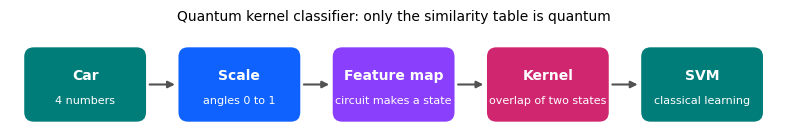

In [82]:
qff.plots.plot_flow(
    [("Car", "4 numbers", "source"), ("Scale", "angles 0 to 1", "move"), ("Feature map", "circuit makes a state", "store"),
     ("Kernel", "overlap of two states", "use"), ("SVM", "classical learning", "source")],
    title="Quantum kernel classifier: only the similarity table is quantum");

**Symbol table** (keep it open while you read; the right column is where the symbol lives in the code).

| Symbol | Meaning | In the code |
|---|---|---|
| $x=(\text{soc},\text{hours},\text{price},\text{load})$ | one car's four numbers | `X`, `X_train[i]` |
| $y\in\{0,1\}$ | label: should this car discharge now? | `y`, `y_train` |
| $f(x)$ | the classifier's decision (sign of the score) | `svm.predict`, `qsvc.predict` |
| $K(a,b)$ | similarity of two cars (the kernel) | `K_train[i, j]`, `kernel_entry(a, b)` |
| $\gamma$ | width of the RBF kernel | `SVC(kernel="rbf")` (default `gamma="scale"`) |
| $\lvert\phi(x)\rangle=U(x)\lvert0\ldots0\rangle$ | the quantum state of a car | `fm.assign_parameters(x)` |
| $\alpha_i,\ b$ | the SVM's weights and offset | `qsvc`, `svm.dual_coef_` |
| $M,\ N$ | shots per circuit; number of cars | `shots`, `len(X_train)` |

<div style="border:1px solid rgba(15,98,254,0.35);border-left:6px solid #0F62FE;background:rgba(15,98,254,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#0F62FE;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">∑ Math · رياضيات</span>&nbsp; **The line to remember**

**The one line to remember.** $K(a,b)=\bigl|\langle\phi(a)|\phi(b)\rangle\bigr|^2$ is the fraction of runs that return $0000$ when you run the circuit for car $a$ and then the undo of the circuit for car $b$ (equation 9). Everything else in the classifier stays classical.

</div>

### 3.1 · A line, a similarity table, and the SVM

**Classification.** We want a rule that says "discharge" or "do not discharge" from a car's four numbers $x=(\text{soc},\text{hours},\text{price},\text{load})$. We learn it from labelled examples (the 60 *training* cars) and judge it on cars it has not seen (the 20 *test* cars): the share it gets right is its **accuracy**.

**A straight line.** A **support vector machine (SVM)** draws the dividing line $w\cdot x+b=0$ that leaves the widest empty gap (the **margin**) between the two groups; a car is classified by the sign of

$$f(x)=w\cdot x+b \tag{1}$$

If no straight line separates the groups, we can first *re-describe* each car by a richer list of numbers $\phi(x)$ and draw the line there. The trick that makes this cheap is that the SVM never needs $\phi(x)$ itself, only the **similarity** of every pair of cars, the **kernel**

$$K(a,b)=\langle\phi(a),\phi(b)\rangle\qquad(\text{an inner product: sum of products of matching entries}) \tag{2}$$

so the learned rule becomes a weighted vote of the training cars, each voting by how similar it is to the new car:

$$f(x)=\sum_{i\in\text{training}}\alpha_i\,y_i\,K(x_i,x)+b \tag{3}$$

($y_i=\pm1$ is the label of training car $i$; the weights $\alpha_i\ge0$ are found by the SVM, and most are 0.) **All the SVM needs is the table $K$ of similarities, the *kernel matrix*.** The classical **RBF** kernel is the similarity (R) of T1:

$$K_{\text{RBF}}(a,b)=e^{-\gamma\lVert a-b\rVert^2} \tag{4}$$

A **quantum kernel** replaces (4) by a similarity computed by a quantum circuit. Everything else, equations (1) to (3), stays classical.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Support vector machine (SVM) | آلة المتجهات الداعمة | I | Accuracy | الدقة | I |
| Kernel | النواة | I | Training data / test data | بيانات التدريب / بيانات الاختبار | I |
| Quantum kernel | النواة الكمية | G | Margin | الهامش | I |
| Feature map | خريطة السمات | I | Similarity | التشابه | I |
| Classifier | المصنِّف | I | Quantum machine learning | تعلم الآلة الكمومي | I |

two features only: straight-line SVM test accuracy 0.80 (all four features: 0.75)


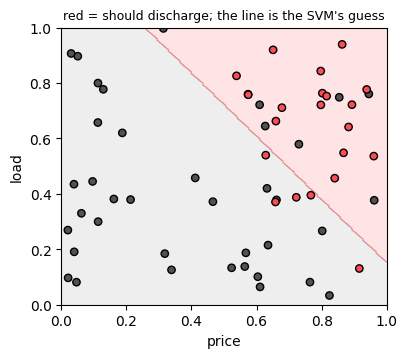

In [83]:
# Primer: a straight-line SVM on two features, price and load.
from matplotlib.colors import ListedColormap

two = [FEATURES.index("price"), FEATURES.index("load")]
svm2 = SVC(kernel="linear", C=10).fit(X_train[:, two], y_train)
gx, gy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
zone = svm2.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.contourf(gx, gy, zone, alpha=0.15, cmap=ListedColormap(["#8D8D8D", "#FA4D56"]))
ax.scatter(*X_train[:, two].T, c=np.where(y_train == 1, "#FA4D56", "#525252"), edgecolors="k", s=28)
ax.set_xlabel("price"); ax.set_ylabel("load")
ax.set_title("red = should discharge; the line is the SVM's guess", fontsize=9)
print(f"two features only: straight-line SVM test accuracy {svm2.score(X_test[:, two], y_test):.2f} (all four features: {acc_linear:.2f})")

In [84]:
# Equation (R) of T1, which is the same formula as equation (4): K_RBF(a, b) = exp(-gamma |a - b|^2), by hand and against scikit-learn: two cars at squared distance 0.25 with gamma = 1 score exp(-0.25) = 0.78.
from sklearn.metrics.pairwise import rbf_kernel

a_demo, b_demo = np.array([0.2, 0.5, 0.5, 0.5]), np.array([0.7, 0.5, 0.5, 0.5])          # they differ in one feature by 0.5
K_rbf_demo = np.exp(-1.0 * np.sum((a_demo - b_demo) ** 2))
print(f"squared distance {np.sum((a_demo - b_demo) ** 2):.2f} -> K_RBF = exp(-0.25) = {K_rbf_demo:.4f}")
assert abs(K_rbf_demo - rbf_kernel([a_demo], [b_demo], gamma=1.0)[0, 0]) < 1e-12, "equation (4) should match scikit-learn"
print("OK: equation (4) matches scikit-learn's rbf_kernel.")

# Equation (3): f(x) = sum_i alpha_i y_i K(x_i, x) + b, rebuilt from the trained RBF model `rbf` of T1.
# `dual_coef_` holds alpha_i * y_i (one number per support vector), `support_vectors_` are the x_i, `intercept_` is b.
g = 1 / (X_train.shape[1] * X_train.var())                                    # scikit-learn's default "scale" width gamma
f_manual = rbf.dual_coef_ @ rbf_kernel(rbf.support_vectors_, X_test, gamma=g) + rbf.intercept_
assert np.allclose(f_manual.ravel(), rbf.decision_function(X_test)), "equation (3) should reproduce the decision function"
print("OK: equation (3) reproduces scikit-learn's decision function for all", len(X_test), "test cars.")

squared distance 0.25 -> K_RBF = exp(-0.25) = 0.7788
OK: equation (4) matches scikit-learn's rbf_kernel.
OK: equation (3) reproduces scikit-learn's decision function for all 20 test cars.


### 3.2 · Features become angles: scaling

A feature map uses each feature as a rotation **angle**, so the *range* of the numbers matters a great deal (we will see how much). We rescale every feature linearly to the interval $[a,b]$ using the training cars only (the test cars must not leak into the scaling):

$$x'=a+(b-a)\,\frac{x-x_{\min}}{x_{\max}-x_{\min}} \tag{5}$$

with $x_{\min},x_{\max}$ the smallest and largest value of that feature *in the training set*. We start with $[a,b]=[0,1]$ (angles up to about 57°).

<div style="border:1px solid rgba(0,125,121,0.35);border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">💡 Idea · فكرة</span>

**A number becomes a turn.** Think of each feature as a dial. The circuit will turn qubit $i$ by an angle that grows with $x_i'$, so two cars whose feature values are close end up with nearly the same state, and cars far apart end up with very different states. The scaling decides *how far round the dial the biggest difference can reach*: a short turn (range 0 to 1) keeps all cars within one quarter of a turn of each other; a long turn (0 to $\pi$) lets the two most different cars land on the *same* spot again (section 3.5 shows why that hurts).

</div>

<div style="border:1px solid rgba(138,63,252,0.35);border-left:6px solid #8A3FFC;background:rgba(138,63,252,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#8A3FFC;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">⚠️ Watch out · انتبه</span>

**Fit the scaler on the training cars only.** The minimum and maximum in equation (5) come from the 60 training cars; the 20 test cars are scaled with those same numbers, so a test value can land a little *outside* $[0,1]$. That is correct and expected. Refitting the scaler on the test cars (or on all 80) would let information about the hidden cars leak into the model, and the test accuracy would no longer be an honest number. The cell below checks equation (5) by hand and counts how many test values fall outside.

</div>

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Scaling | تحجيم المقياس | I | Data leakage | تسرّب البيانات | I |
| Feature | السمة | I | Angle | الزاوية | I |

training features now run from 0.0 to 1.0
test values outside [0, 1]: 4 of 80 (expected: they are scaled with the training range)
OK: equation (5) reproduces the scaler; the training cars fill [0, 1]; the test cars may sit slightly outside.


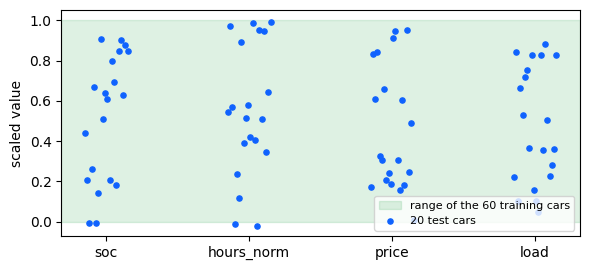

In [85]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler((0, 1)).fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("training features now run from", X_train_s.min().round(2), "to", X_train_s.max().round(2))

# Equation (5) by hand: every car, test cars included, is scaled with the TRAINING minimum and maximum.
lo, hi = X_train.min(axis=0), X_train.max(axis=0)
assert np.allclose((X_test - lo) / (hi - lo), X_test_s), "equation (5) should match MinMaxScaler"
assert np.allclose(X_train_s.min(axis=0), 0) and np.allclose(X_train_s.max(axis=0), 1), "the training cars fill [0, 1] exactly"
outside = int(((X_test_s < 0) | (X_test_s > 1)).sum())
print(f"test values outside [0, 1]: {outside} of {X_test_s.size} (expected: they are scaled with the training range)")
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.axhspan(0, 1, color="#24A148", alpha=0.15, label="range of the 60 training cars")
for j, name in enumerate(FEATURES):
    ax.scatter(np.full(len(X_test_s), j) + np.linspace(-0.15, 0.15, len(X_test_s)), X_test_s[:, j], s=14, color="#0F62FE", label="20 test cars" if j == 0 else None)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES); ax.set_ylabel("scaled value"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
print("OK: equation (5) reproduces the scaler; the training cars fill [0, 1]; the test cars may sit slightly outside.")

### 3.3 · The quantum feature map: a car becomes a state

**Amplitudes and states.** $n$ qubits hold a list of $2^n$ numbers called **amplitudes**; the squared size of each is the **probability** of measuring that outcome. A **feature map** is a circuit $U(x)$ that starts from all qubits in $|0\rangle$ and, using the car's numbers as rotation angles, prepares a state that depends on the car:

$$|\phi(x)\rangle=U(x)\,|0\ldots0\rangle \tag{6}$$

**The simplest map (one qubit per feature, no entanglement).** A Hadamard gate $H$ turns $|0\rangle$ into the equal mixture $\frac1{\sqrt2}(|0\rangle+|1\rangle)$; a phase gate $P(2x)$ then multiplies the $|1\rangle$ part by $e^{2ix}$ (a **phase**: a turn by the angle $2x$; $e^{i\theta}=\cos\theta+i\sin\theta$ is a point on a circle of radius 1). For one feature:

$$|\phi(x)\rangle=\tfrac1{\sqrt2}\bigl(|0\rangle+e^{2ix}|1\rangle\bigr) \tag{7}$$

This is Qiskit's `z_feature_map` (one repetition). **The standard map with entanglement**, `zz_feature_map`, adds for every *pair* of features $i<j$ a coupling between their qubits (a CX gate, a phase gate, and the same CX gate again) with angle $2(\pi-x_i)(\pi-x_j)$:

$$|\phi(x)\rangle=\prod_{i<j}\Bigl[\text{CX}_{ij}\,P_j\bigl(2(\pi-x_i)(\pi-x_j)\bigr)\,\text{CX}_{ij}\Bigr]\ \prod_iP_i(2x_i)\ H^{\otimes4}|0000\rangle \tag{8}$$

(with `reps=2` the whole block is repeated). **Entanglement** here means the qubits' states are tied together by the pair terms, so the state cannot be written as one independent state per qubit.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Feature map | خريطة السمات | I | Hadamard gate | بوابة هادامارد | G |
| Amplitude | السعة | G | Rotation angle | زاوية الدوران | I |
| Phase | الطور | U | Quantum circuit | الدائرة الكمومية | U |
| Entanglement | التشابك | G | Quantum state | الحالة الكمومية | I |

feature-map parameters (one per feature): [ParameterVectorElement(x[0]), ParameterVectorElement(x[1]), ParameterVectorElement(x[2]), ParameterVectorElement(x[3])]


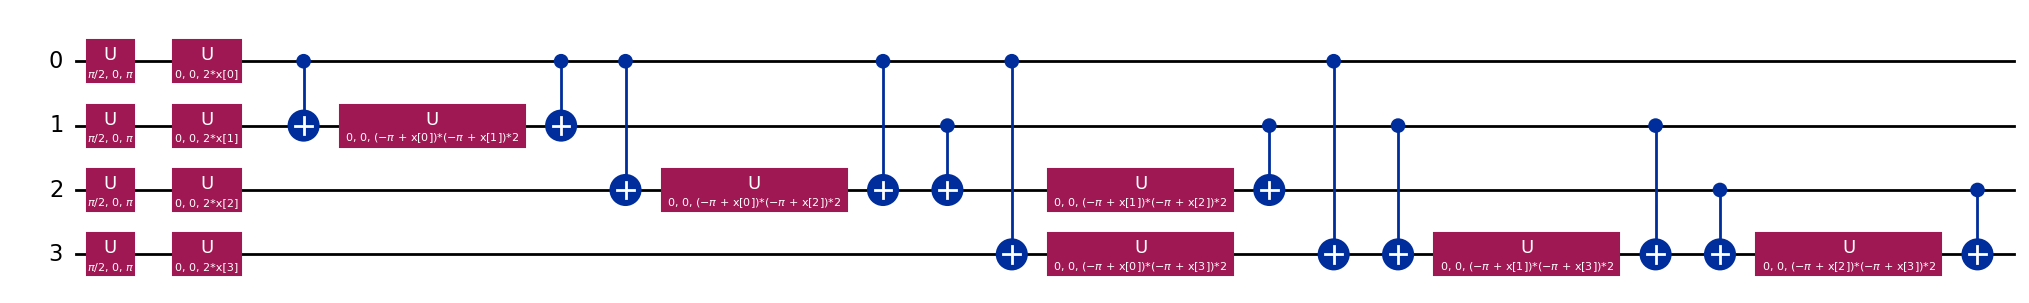

car A (label 0): [0.23 0.94 0.08 0.43]   car B (label 0): [0.24 0.93 0.58 0.16]
the two cars' states differ; their overlap |<a|b>|^2 = 0.117


In [86]:
from qiskit.circuit.library import zz_feature_map, z_feature_map
from qiskit.quantum_info import Statevector

fm = zz_feature_map(QUBITS, reps=1)
print("feature-map parameters (one per feature):", list(fm.parameters))
try:
    display(fm.decompose().draw("mpl", fold=30))
except Exception:                                      # drawing with matplotlib needs pylatexenc; fall back to text
    print(fm.decompose().draw("text", fold=120))

car_a, car_b = X_train_s[0], X_train_s[1]
state_a = Statevector(fm.assign_parameters(car_a))      # equation (6): |phi(x)> = U(x)|0...0> for car A
state_b = Statevector(fm.assign_parameters(car_b))      # equation (6) again, for car B
print(f"car A (label {y_train[0]}): {np.round(car_a, 2)}   car B (label {y_train[1]}): {np.round(car_b, 2)}")
print("the two cars' states differ; their overlap |<a|b>|^2 =", round(abs(state_a.inner(state_b)) ** 2, 3))

In [87]:
# Equation (8) with plain gates, checked against Qiskit's zz_feature_map: the same state, up to a global phase.
from qiskit import QuantumCircuit


def zz_by_hand(x):
    """H on every qubit, P(2 x_i) on qubit i, then for every pair i < j: CX, P(2 (pi - x_i)(pi - x_j)) on j, CX."""
    n = len(x)
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for i in range(n):
        qc.p(2 * x[i], i)
    for i in range(n):
        for j in range(i + 1, n):
            qc.cx(i, j)
            qc.p(2 * (np.pi - x[i]) * (np.pi - x[j]), j)
            qc.cx(i, j)
    return qc


car0 = X_train_s[0]
same_state = Statevector(zz_by_hand(car0)).equiv(Statevector(fm.assign_parameters(car0)))
assert same_state, "equation (8) should reproduce Qiskit's zz_feature_map"
print("hand-built equation (8) == zz_feature_map(4, reps=1) (same state up to a global phase):", same_state)
print("gates in the hand-built map:", dict(zz_by_hand(car0).count_ops()), "(4 H, 4 P for the features, 6 pairs x (2 CX + 1 P))")

hand-built equation (8) == zz_feature_map(4, reps=1) (same state up to a global phase): True
gates in the hand-built map: {'cx': 12, 'p': 10, 'h': 4} (4 H, 4 P for the features, 6 pairs x (2 CX + 1 P))


### 3.4 · The quantum kernel: how much two states overlap

Two cars $a$ and $b$ give two states $|\phi(a)\rangle$ and $|\phi(b)\rangle$. Their **overlap** $\langle\phi(a)|\phi(b)\rangle$ is an inner product of the two amplitude lists (with complex conjugation on the first); its squared size is a number between 0 (states completely different) and 1 (identical states): the **quantum kernel**

$$K(a,b)=\bigl|\langle\phi(a)|\phi(b)\rangle\bigr|^2=P\bigl(\text{measuring }0000\ \text{after }U(a)\text{ then }U(b)^\dagger\bigr) \tag{9}$$

The second form is how a device does it: run the circuit for car $a$, then the *undo* ($U^\dagger$, the inverse) of the circuit for car $b$, and measure. If the two states are the same, the undo works perfectly and every run gives $0000$, so $K=1$; otherwise $K$ is the *fraction of runs* that give $0000$. A simulator can also read $K$ exactly from the statevectors.

**A worked example you can check on paper (one qubit).** With the simplest map (7), the overlap of cars with feature values $a$ and $b$ is $\frac12\bigl(1+e^{2i(b-a)}\bigr)$ and its squared size is

$$K(a,b)=\cos^2(a-b)\ \text{ for one feature},\qquad K(a,b)=\prod_{i=1}^4\cos^2(a_i-b_i)\ \text{ for the four-qubit Z map} \tag{10}$$

Because there is no entanglement, the four qubits are independent and the kernel is a product. (With two repetitions, as in the best row of T3, each factor is a different function of the two feature values, but it is still a product of four single-qubit factors, so the conclusions below still hold.) For $a=0.2$ and $b=0.9$: $K=\cos^2(0.7)=0.585$. **Two things follow.** (i) $\cos^2(\Delta)\approx e^{-\Delta^2}$ for small differences $\Delta$: the Z-map kernel behaves like an RBF kernel with $\gamma=1$, which is why it can tie the classical one. (ii) A kernel with this product form costs a classical computer 4 cosines per pair of cars: **it is trivially easy to simulate**, so a good result with it is no quantum advantage. With the ZZ map (8) there is no such formula, but the cost of computing it exactly on a classical computer grows quickly with the number of qubits.

<div style="border:1px solid rgba(138,63,252,0.35);border-left:6px solid #8A3FFC;background:rgba(138,63,252,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#8A3FFC;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">⚠️ Watch out · انتبه</span>

**Kernel concentration.** If the off-diagonal similarities are all small, the kernel matrix is close to the *identity matrix* (every car is similar only to itself): the SVM can then fit any labels on the training cars (memorise them) but has little to say about new cars. This is **overfitting**, and the plots below show how strongly it affects the ZZ map.

</div>

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Overlap | التراكب (التداخل الجزئي) بين حالتين | I | Inverse circuit | الدائرة العكسية | I |
| Inner product | الجداء الداخلي | I | Probability | الاحتمال | I |
| Kernel matrix | مصفوفة النواة | I | Measurement | القياس | G |
| Overfitting | الإفراط في الملاءمة | I |  |  |  |

In [88]:
# Equation (10) in code: the Z-map kernel is a product of cos^2 of the feature differences, checked against Qiskit.
from qiskit.circuit.library import z_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel as _Fidelity

K_one = _Fidelity(feature_map=z_feature_map(1, reps=1)).evaluate(np.array([[0.2], [0.9]]))
print(f"one qubit, a = 0.2, b = 0.9: Qiskit {K_one[0, 1]:.4f} | cos^2(0.7) = {np.cos(0.7) ** 2:.4f}")
assert abs(K_one[0, 1] - np.cos(0.7) ** 2) < 1e-12
K_z = _Fidelity(feature_map=z_feature_map(QUBITS, reps=1)).evaluate(X_train_s)
K_prod = np.prod(np.cos(X_train_s[:, None, :] - X_train_s[None, :, :]) ** 2, axis=2)
print("four-qubit Z map: largest difference between Qiskit's 60x60 table and the product of cos^2:", np.abs(K_z - K_prod).max())
assert np.allclose(K_z, K_prod, atol=1e-10), "equation (10) should reproduce the Z-map kernel"
K_gauss = np.exp(-((X_train_s[:, None, :] - X_train_s[None, :, :]) ** 2).sum(axis=2))
print(f"cos^2 product against exp(-distance^2): average difference {np.abs(K_prod - K_gauss).mean():.3f}, largest {np.abs(K_prod - K_gauss).max():.3f}")
# Equation (7): for one qubit the Z map gives (|0> + e^{2ix}|1>)/sqrt(2); here x = 0.3, equal up to a global phase.
state_one = Statevector(z_feature_map(1, reps=1).assign_parameters([0.3]))
assert state_one.equiv(Statevector(np.array([1, np.exp(2j * 0.3)]) / np.sqrt(2))), "equation (7) should describe the one-qubit Z map"
print("OK: equation (7), the one-qubit Z-map state, matches Qiskit up to a global phase.")
print("OK: this quantum kernel is a product of cosines: a classical computer gets it from 4 cosines per pair.")

one qubit, a = 0.2, b = 0.9: Qiskit 0.5850 | cos^2(0.7) = 0.5850
four-qubit Z map: largest difference between Qiskit's 60x60 table and the product of cos^2: 1.7763568394002505e-15
cos^2 product against exp(-distance^2): average difference 0.020, largest 0.073
OK: equation (7), the one-qubit Z-map state, matches Qiskit up to a global phase.
OK: this quantum kernel is a product of cosines: a classical computer gets it from 4 cosines per pair.


<div style="border:2px dashed #007D79;border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🧪 Try it · جرّب</span>

**Do it by hand.** Pick two cars, for example `i, j = 0, 1`, and compute `np.prod(np.cos(X_train_s[i] - X_train_s[j]) ** 2)`. Compare it with `K_z[i, j]` from the cell above. Then find the pair of cars with the *smallest* `K_z` (hint: `np.argmin` on the table, or look at `np.unravel_index`) and print their four scaled features. Which feature differs most, and does that match the cos² picture?

</div>

**Step 3: the whole similarity table, exactly.** `FidelityStatevectorKernel` computes every K(a, b) from the exact statevectors of the simulator, so it takes well under a second. We then sort the 60 cars by label and draw K as a heat map: a kernel that separates the classes well would show brighter blocks along the diagonal. Look at how faint any such blocks are, and read the two averages printed under the picture: most pairs of cars score low (around 0.1), and the gap between same-class and different-class pairs is small. The SVM can still use small differences, but this is not a sharp picture. One more property worth checking: a table of squared overlaps is a valid kernel matrix, which means it is symmetric and has no negative eigenvalue (the SVM's mathematics needs that); the cell prints the smallest eigenvalue.

K is symmetric: True | every car is identical to itself (diagonal = 1): True
smallest eigenvalue of K: 6.29e-02 (a valid kernel matrix never goes below 0, up to rounding)
mean similarity: same-class pairs 0.126, different-class pairs 0.120


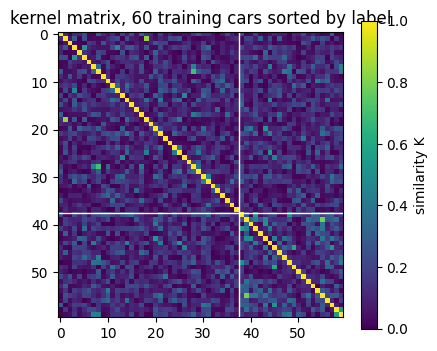

In [89]:
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

qk = FidelityStatevectorKernel(feature_map=fm)
K_train = qk.evaluate(X_train_s)                      # 60 x 60 table of similarities
order = np.argsort(y_train, kind="stable")             # no-discharge cars first, then discharge cars
n_no = int((y_train == 0).sum())
print("K is symmetric:", np.allclose(K_train, K_train.T), "| every car is identical to itself (diagonal = 1):", np.allclose(np.diag(K_train), 1))
smallest = np.linalg.eigvalsh(K_train).min()                  # a similarity table made of overlaps has no negative eigenvalue
print(f"smallest eigenvalue of K: {smallest:.2e} (a valid kernel matrix never goes below 0, up to rounding)")
assert smallest > -1e-9, "a table of squared overlaps should be positive semi-definite"
fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(K_train[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
ax.axhline(n_no - 0.5, color="w", lw=1); ax.axvline(n_no - 0.5, color="w", lw=1)
ax.set_title("kernel matrix, 60 training cars sorted by label"); fig.colorbar(im, ax=ax, label="similarity K")
same = (y_train[:, None] == y_train[None, :]) & ~np.eye(len(y_train), dtype=bool)
print(f"mean similarity: same-class pairs {K_train[same].mean():.3f}, different-class pairs {K_train[y_train[:, None] != y_train[None, :]].mean():.3f}")

**A closer look: 12 cars.** Sixty rows is too many to read. Here are 12 cars, the first 6 "no" and the first 6 "discharge" in the training set, with their kernel matrix and where they sit on the price-load map.

12 cars: similarity inside 'no' 0.126 | inside 'discharge' 0.214 | across the two groups 0.126
car   soc  hours price  load  label
  0  0.32  0.93  0.10  0.44  0
  1  0.32  0.91  0.57  0.19  0
  2  0.88  0.37  0.05  0.90  0
  3  0.22  0.65  0.16  0.38  0
  4  0.43  0.82  0.02  0.10  0
  5  0.43  0.95  0.34  0.13  0
  6  0.71  0.45  0.57  0.76  1
  7  0.70  0.73  0.89  0.72  1
  8  0.37  0.81  0.72  0.39  1
  9  0.89  0.69  0.87  0.55  1
 10  0.13  0.88  0.92  0.13  1
 11  0.35  0.88  0.63  0.54  1


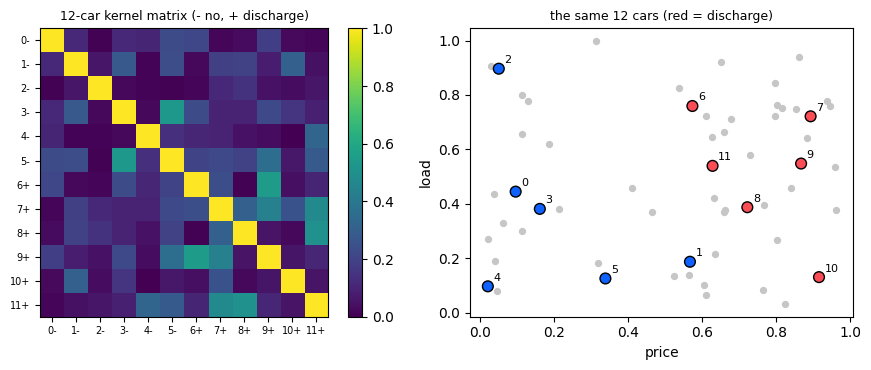

In [90]:
no_idx = [i for i in range(len(y_train)) if y_train[i] == 0][:6]
yes_idx = [i for i in range(len(y_train)) if y_train[i] == 1][:6]
twelve = no_idx + yes_idx                              # indices into the training set
K12 = K_train[np.ix_(twelve, twelve)]
labels12 = [f"{k}{'+' if y_train[i] else '-'}" for k, i in enumerate(twelve)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
im = axes[0].imshow(K12, cmap="viridis", vmin=0, vmax=1)
axes[0].set_xticks(range(12)); axes[0].set_xticklabels(labels12, fontsize=7); axes[0].set_yticks(range(12)); axes[0].set_yticklabels(labels12, fontsize=7)
axes[0].set_title("12-car kernel matrix (- no, + discharge)", fontsize=9); fig.colorbar(im, ax=axes[0])
axes[1].scatter(*X_train[:, two].T, c="#C6C6C6", s=18, label="other training cars")
axes[1].scatter(*X_train[twelve][:, two].T, c=np.where(y_train[twelve] == 1, "#FA4D56", "#0F62FE"), edgecolors="k", s=60)
for k, i in enumerate(twelve):
    axes[1].annotate(str(k), X_train[i, two], textcoords="offset points", xytext=(4, 4), fontsize=8)
axes[1].set_xlabel("price"); axes[1].set_ylabel("load"); axes[1].set_title("the same 12 cars (red = discharge)", fontsize=9)
plt.tight_layout()
inside_yes = K12[6:, 6:][~np.eye(6, dtype=bool)].mean()
inside_no = K12[:6, :6][~np.eye(6, dtype=bool)].mean()
across = K12[:6, 6:].mean()
print(f"12 cars: similarity inside 'no' {inside_no:.3f} | inside 'discharge' {inside_yes:.3f} | across the two groups {across:.3f}")
print("car   soc  hours price  load  label")
for k, i in enumerate(twelve):
    print(f"{k:>3}  " + "  ".join(f"{v:.2f}" for v in X_train[i]) + f"  {y_train[i]}")

**Kernel concentration, in one picture.** The histograms show the off-diagonal similarities (pairs of *different* training cars) for four kernels. The ZZ map with angles up to $\pi$ squeezes almost every pair towards 0; the plain ZZ map at 0-1 is better but still low; the Z map and the classical RBF kernel spread their values out. A kernel matrix with values squeezed near 0 is close to the identity matrix: the SVM memorises the training cars.

{'ZZ map, 0-pi': 0.071, 'ZZ map, 0-1': 0.123, 'Z map, 0-1': 0.508, 'classical RBF': 0.227}


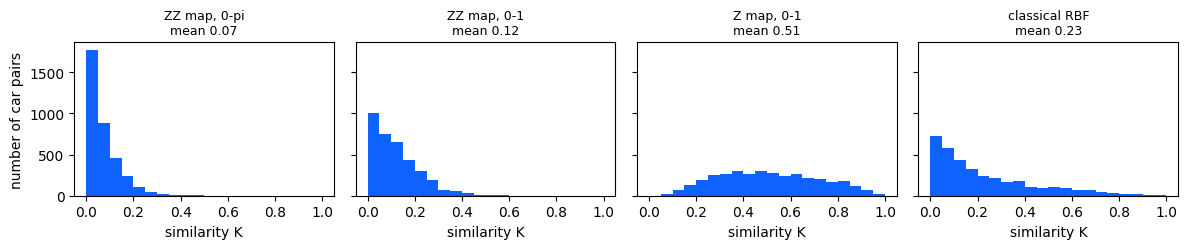

In [91]:
# Off-diagonal similarities of four kernels on the 60 training cars (pairs of different cars).
sc_pi = MinMaxScaler((0, np.pi)).fit(X_train)
K_zz_pi = FidelityStatevectorKernel(feature_map=fm).evaluate(sc_pi.transform(X_train))
K_rbf_train = rbf_kernel(X_train, gamma=1 / (X_train.shape[1] * X_train.var()))                      # scikit-learn's default width
offdiag = ~np.eye(len(X_train), dtype=bool)
kernels = {"ZZ map, 0-pi": K_zz_pi, "ZZ map, 0-1": K_train, "Z map, 0-1": K_z, "classical RBF": K_rbf_train}
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), sharey=True)
for ax, (name, Kmat) in zip(axes, kernels.items()):
    ax.hist(Kmat[offdiag], bins=20, range=(0, 1), color="#0F62FE")
    ax.set_title(f"{name}\nmean {Kmat[offdiag].mean():.2f}", fontsize=9); ax.set_xlabel("similarity K")
axes[0].set_ylabel("number of car pairs")
plt.tight_layout()
print({name: round(float(Kmat[offdiag].mean()), 3) for name, Kmat in kernels.items()})

### T2 · Core step: one kernel entry by hand, and the QSVC · التمرين ٢

**What you are about to build, and why.** The kernel table in the previous cell was computed exactly by the simulator from the statevectors. A real device cannot do that: it estimates *each* entry from repeated runs, as equation (9) says. In T2 you compute **one** entry the way a device would, for cars 0 and 1: build the circuit "feature map of car a, then the *inverse* of the feature map of car b", measure all four qubits many times, and count the fraction of runs that give `0000`. You compare it with the exact table, and then you train the full quantum-kernel classifier, Qiskit's `QSVC`, on the 60 training cars and read its test accuracy.

**The formula you implement:** equation (9), second form: $K(a,b)=\text{(number of runs giving 0000)}/\text{(number of runs)}$. A car compared with itself must give exactly 1.

**Stuck? Open the hints one at a time, and try again after each. · تلميحات**

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 1 · a nudge · تلميح ١</summary>

Look at equation (9): the circuit has two halves. The first half is the feature map for car a. The second half is the *undo* of the feature map for car b. Two circuits are joined with a method of the first one. To count outcomes you must measure all qubits. Ask yourself two things first: why does a car compared with itself have to give exactly 1, and which objects do you already have from section 3 that you can reuse (the feature map `fm` and the kernel object `qk`)?

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 2 · the structure · تلميح ٢</summary>

Steps inside `kernel_entry`: assign car a's numbers to the feature map; assign car b's numbers to a copy and take its inverse; compose them; measure all qubits; run the circuit with a `StatevectorSampler` (seeded, `shots` runs) and read the counts of the register `meas`; the answer is the share of runs that gave all zeros. Then compute the two entries and train `QSVC` with the kernel object `qk` on the scaled training data.

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 3 · nearly there · تلميح ٣</summary>

```python
def kernel_entry(x_a, x_b, shots=4096):
    qc = ______               # feature map of car a, then the undo of the feature map of car b
    ______                    # measure all qubits
    counts = ______           # run it with the seeded sampler and read the counts
    return ______             # the share of runs that gave 0000
k_manual_same = ______        # a car against itself
k_manual_pair = ______        # cars 0 and 1
qsvc = ______                 # the quantum-kernel classifier, trained on the scaled training cars
acc_qsvc_train, acc_qsvc = ______, ______
```
Self-check targets: the same-car entry is exactly 1, the pair entry matches the exact table within about 0.03, and the QSVC test accuracy is about 0.70.

</details>

In [94]:
# TODO (team) T2: compute one kernel entry by hand, check it against the table, train QSVC
# Goal: kernel_entry(x_a, x_b, shots=4096) estimates one kernel entry the way a device would (equation 9, second form);
# keep k_manual_same (car 0 with itself) and k_manual_pair (cars 0 and 1). Then train the quantum-kernel classifier `qsvc`
# (kernel object `qk`, C = 10) on the scaled training cars, and keep acc_qsvc_train and acc_qsvc.
def kernel_entry(x_a, x_b, shots=4096):
    qc = fm.assign_parameters(x_a).compose(fm.assign_parameters(x_b).inverse())
    qc.measure_all()
    counts = StatevectorSampler(seed=SEED, default_shots=shots).run([qc]).result()[0].data.meas.get_counts()
    return counts.get("0000", 0) / shots


k_manual_same = kernel_entry(X_train_s[0], X_train_s[0])
k_manual_pair = kernel_entry(X_train_s[0], X_train_s[1])
print(f"same car: {k_manual_same:.4f} | cars 0 and 1: {k_manual_pair:.4f} | exact table: {K_train[0, 1]:.4f}")

same car: 1.0000 | cars 0 and 1: 0.1106 | exact table: 0.1168


In [95]:
# Self-check
assert abs(k_manual_same - 1.0) < 1e-9, "T2: a car must be identical to itself, K = 1"
assert abs(k_manual_pair - K_train[0, 1]) < 0.03, "T2: the circuit estimate should match the exact table within 0.03"
assert 0.6 <= acc_qsvc <= 0.85, "T2: QSVC test accuracy should be about 0.70"

### 3.5 · The same classifier with different circuits and scalings

Two choices change the kernel: the **feature map** (how the car's numbers become a state) and the **scaling** (how large the angles get). By equation (10) the Z-map kernel depends on the feature differences through $\cos^2(\Delta)$, which is **periodic**: it has period $\pi$, so two values that differ by exactly $\pi$ look *identical*. If we scale the features to $[0,\pi]$, the two most different cars (a difference of $\pi$ in a feature) get $K=1$ in that feature, as if they were the same car. Scaling to $[0,1]$ keeps every difference inside $[0,1]$ where $\cos^2$ falls steadily from 1 to $0.29$. The ZZ map has the same wrap-around problem, only worse. The cell below draws the curve and the two ranges, and then T3 measures what it does to accuracy. `z_feature_map` has no entanglement (each qubit is treated alone), which makes it easy to simulate on an ordinary computer. We report every row, good or bad.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Periodic function | دالة دورية | I | Repetitions (reps) | التكرارات | I |
| Period | الدور (الدورة) | I |  |  |  |

scaled to 0-1: cos^2 stays between 0.29 and 1 | scaled to 0-pi: a difference of pi/2 gives K = 0.00 and a difference of pi gives K = 1.00
a = 0.2, b = 0.9: K = 0.5850 | b moved by pi: K = 0.5850   (the kernel cannot see a shift of pi)
OK: the kernel is periodic with period pi; scaling to 0-pi makes the most different cars look identical in that feature.


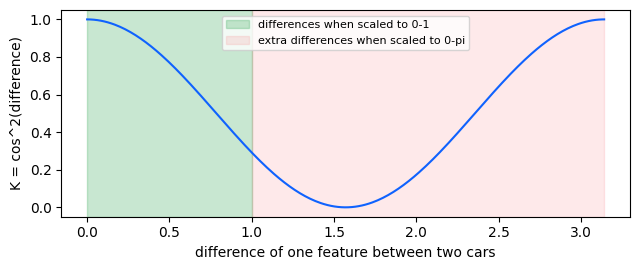

In [96]:
# Why the scaling matters: cos^2 of a feature difference, over the range of differences each scaling allows.
delta = np.linspace(0, np.pi, 300)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(delta, np.cos(delta) ** 2, color="#0F62FE")
ax.axvspan(0, 1, color="#24A148", alpha=0.25, label="differences when scaled to 0-1")
ax.axvspan(1, np.pi, color="#FA4D56", alpha=0.12, label="extra differences when scaled to 0-pi")
ax.set_xlabel("difference of one feature between two cars"); ax.set_ylabel("K = cos^2(difference)"); ax.legend(fontsize=8)
plt.tight_layout()
print(f"scaled to 0-1: cos^2 stays between {np.cos(1) ** 2:.2f} and 1 | scaled to 0-pi: a difference of pi/2 gives K = {np.cos(np.pi / 2) ** 2:.2f} and a difference of pi gives K = {np.cos(np.pi) ** 2:.2f}")
# The same thing in Qiskit itself: move one car's feature by exactly pi and the one-qubit Z-map kernel does not change.
k1 = _Fidelity(feature_map=z_feature_map(1, reps=1))
K_before = k1.evaluate(np.array([[0.2], [0.9]]))[0, 1]
K_shifted = k1.evaluate(np.array([[0.2], [0.9 + np.pi]]))[0, 1]
print(f"a = 0.2, b = 0.9: K = {K_before:.4f} | b moved by pi: K = {K_shifted:.4f}   (the kernel cannot see a shift of pi)")
assert abs(K_before - K_shifted) < 1e-9, "cos^2 has period pi, so the Z-map kernel cannot tell b from b + pi"
print("OK: the kernel is periodic with period pi; scaling to 0-pi makes the most different cars look identical in that feature.")

### T3 · Stretch: three circuits, two scalings, and what the table says · التمرين ٣

**What you are about to build, and why.** The honest test of a quantum kernel is not one number but a table: change the feature map and the scaling, and report *every* row, good or bad, next to the classical baseline. In T3 you loop over three feature maps (`zz_feature_map` with one repetition, `zz_feature_map` with two repetitions and linear entanglement, and `z_feature_map` with two repetitions) and two scalings (0 to 1 and 0 to $\pi$), train a `QSVC` for each of the six combinations, and store test and training accuracy. Then you write one or two sentences saying which row is best, which is worst, and why the scaling matters, using what you learned in 3.4 and 3.5.

**The formulas you use:** equation (5) for the two scalings (`MinMaxScaler((0, 1))` and `MinMaxScaler((0, np.pi))`, fitted on the training cars only) and the kernel (9) inside `FidelityStatevectorKernel`.

**Stuck? Open the hints one at a time, and try again after each. · تلميحات**

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 1 · a nudge · تلميح ١</summary>

You are doing the same three things six times: scale the features, build the quantum kernel from a feature map, train `QSVC`, and read two accuracies. What changes between the six runs? Which parts can you put in a dictionary and loop over? Before you code anything, write down which of the six runs you expect to be best and which worst; sections 3.4 and 3.5 contain what you need, and the table will tell you whether you were right.

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 2 · the structure · تلميح ٢</summary>

Define the three feature maps and the two scalings as dictionaries; two nested loops over them. Inside: fit a `MinMaxScaler` with the chosen range on the training cars only, scale both sets, train a `QSVC` whose kernel is a `FidelityStatevectorKernel` built from the feature map, and store its test and training accuracy under the key (map name, scaling name). After the loops write the explanation. Two details: the only thing that differs between the two scalings is the range you give the scaler, and the only thing that differs between the three maps is the feature map you hand to the kernel; and the Self-check reads results by tuple keys such as `("zz1", "unit")`, so your dictionaries need keys of exactly that kind.

</details>

<details style="border:1px solid rgba(128,128,128,0.45);border-radius:8px;padding:4px 12px;margin:6px 0">
<summary style="cursor:pointer;font-weight:600">Hint 3 · nearly there · تلميح ٣</summary>

```python
maps = ______                 # {"zz1": ..., "zz2": ..., "z2": ...} as described in the task
scalings = ______             # {"unit": the range 0 to 1, "pi": the range 0 to pi}
acc_q, acc_q_train = {}, {}
for mname, fmap in maps.items():
    for sname, rng in scalings.items():
        ______                # scale (fit on training only), train QSVC with this map, store both accuracies
explanation = "..."           # which row is best, which is worst, and why scaling matters
```

</details>

In [103]:
# TODO (team) T3: stretch: fill the variations table and explain the best and worst rows
# Goal: for the three feature maps zz1 = zz_feature_map(4, reps=1), zz2 = zz_feature_map(4, reps=2, entanglement="linear"),
# z2 = z_feature_map(4, reps=2) and the two scalings unit = (0, 1), pi = (0, np.pi) (scaler fitted on X_train only), train a quantum-kernel
# QSVC (C = 10) and store test and training accuracy in acc_q[(map_name, scaling_name)] and acc_q_train[...] (six entries each).
# Then write explanation = "...": which row is best, which is worst, and why scaling matters.

maps = {
    "zz1": zz_feature_map(QUBITS, reps=1),
    "zz2": zz_feature_map(QUBITS, reps=2, entanglement="linear"),
    "z2": z_feature_map(QUBITS, reps=2),
}
scalings = {"unit": (0, 1), "pi": (0, np.pi)}


acc_q, acc_q_train = {}, {}
for mname, fmap in maps.items():
    for sname, rng in scalings.items():
        sc = MinMaxScaler(rng).fit(X_train)
        Xtr, Xte = sc.transform(X_train), sc.transform(X_test)
        clf = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fmap), C=10).fit(Xtr, y_train)
        acc_q[(mname, sname)] = clf.score(Xte, y_test)
        acc_q_train[(mname, sname)] = clf.score(Xtr, y_train)
        print(f"{mname:>4} / {sname:<4}  train {acc_q_train[(mname, sname)]:.2f}  test {acc_q[(mname, sname)]:.2f}")

        explanation = "The best row is z2 with unit scaling (test accuracy 0.80), which only ties the classical RBF. The worst row is z2 with pi scaling (test accuracy 0.40). Scaling to 0-pi hurts because the angles wrap around after pi, so very different cars look the same."

 zz1 / unit  train 1.00  test 0.70
 zz1 / pi    train 1.00  test 0.50
 zz2 / unit  train 1.00  test 0.75
 zz2 / pi    train 1.00  test 0.65
  z2 / unit  train 1.00  test 0.80
  z2 / pi    train 1.00  test 0.40


In [104]:
# Self-check
assert len(acc_q) == 6 and len(acc_q_train) == 6, "T3: six rows (3 feature maps x 2 scalings) for test and for train"
assert acc_q[("zz1", "pi")] <= acc_q[("zz1", "unit")], "T3: scaling the ZZ map to 0-pi should be no better than 0-1"
assert isinstance(explanation, str) and len(explanation) > 60, "T3: write your explanation in a sentence or two"

### 3.6 · The kernel the way a device computes it: shots and cost

A real device estimates every entry from $M$ runs (**shots**): $\hat K$ is the fraction of runs that give $0000$, so it carries a random error. If the true value is $K$, the typical size of that error is

$$\sigma_{\hat K}=\sqrt{\frac{K(1-K)}{M}}\ \approx\ 0.009\ \text{ for }K=0.1,\ M=1024,\qquad \text{number of circuits}=\frac{N_{\text{train}}(N_{\text{train}}-1)}2+N_{\text{test}}N_{\text{train}} \tag{11}$$

For our data $60\cdot59/2=1770$ circuits for the training table plus $20\cdot60=1200$ for the test cars: **2 970 circuits** for 80 cars. For 6 000 training cars the table alone has $6000\cdot5999/2\approx18$ million entries: the cost grows with the **square** of the data size. `FidelityQuantumKernel` with a sampler does what a device would (here a simulated sampler, 1 024 shots per circuit by default). The cell below first checks the error formula by simulation, then runs the sampled kernel; it takes about half a minute.

<sub>Arabic terms for this step. Tier G: in Quantabic's glossary. Tier I: proposed, to be checked against quantabic.com.</sub>

| English | العربية | Tier | English | العربية | Tier |
|---|---|---|---|---|---|
| Shots | عدد مرات التشغيل (shots) | I | Error mitigation | تخفيف الأخطاء | I |
| Sampling error | خطأ أخذ العيّنات | I | Quantum advantage | الأفضلية الكمومية | G |
| Noise | الضوضاء | G |  |  |  |

In [105]:
# Equation (11): the error of a shot-based kernel entry, and the number of circuits.
sim = np.random.default_rng(SEED)
K_true, shots_demo = 0.1, 1024
estimates = sim.binomial(shots_demo, K_true, 20000) / shots_demo
print(f"K = {K_true}, {shots_demo} shots: spread of the estimate {estimates.std():.4f} | equation (11): {np.sqrt(K_true * (1 - K_true) / shots_demo):.4f}")
assert abs(estimates.std() / np.sqrt(K_true * (1 - K_true) / shots_demo) - 1) < 0.05
n_tr_, n_te_ = len(X_train_s), len(X_test_s)
print(f"circuits for 60 training + 20 test cars: {n_tr_ * (n_tr_ - 1) // 2} + {n_te_ * n_tr_} = {n_tr_ * (n_tr_ - 1) // 2 + n_te_ * n_tr_}")
print(f"circuits for the training table of 6000 cars: {6000 * 5999 // 2:,}")

K = 0.1, 1024 shots: spread of the estimate 0.0094 | equation (11): 0.0094
circuits for 60 training + 20 test cars: 1770 + 1200 = 2970
circuits for the training table of 6000 cars: 17,997,000


In [106]:
import time
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute

t0 = time.perf_counter()
qk_sampled = FidelityQuantumKernel(feature_map=fm, fidelity=ComputeUncompute(sampler=StatevectorSampler(seed=SEED)))
qsvc_sampled = QSVC(quantum_kernel=qk_sampled, C=10).fit(X_train_s, y_train)
acc_sampled = qsvc_sampled.score(X_test_s, y_test)
sampled_seconds = time.perf_counter() - t0
n_tr, n_te = len(X_train_s), len(X_test_s)
circuits = n_tr * (n_tr - 1) // 2 + n_te * n_tr
print(f"sampled kernel: test accuracy {acc_sampled:.2f} in {sampled_seconds:.0f} s, {circuits} circuits (exact kernel: {acc_qsvc:.2f} in a fraction of a second)")

sampled kernel: test accuracy 0.75 in 21 s, 2970 circuits (exact kernel: 0.70 in a fraction of a second)


<div style="border:2px dashed #007D79;border-left:6px solid #007D79;background:rgba(0,125,121,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#007D79;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🧪 Try it · جرّب</span>

Go back to section 2, change `random_state=7` in the train/test split to another number (for example 3), and rerun the notebook. Which accuracies move, and by how much? Why is one test car worth 5 points, and what does that tell you about trusting a difference of 0.05?

</div>

In [107]:
circuit = fm.assign_parameters(X_train_s[0])        # the main circuit of this notebook: the feature map for one car

### Optional: how this would go to a real IBM Quantum computer
This is a sketch and has not been checked against the current IBM documentation. Nothing here runs in this notebook.

```python
# Not run here. Needs: pip install qiskit-ibm-runtime, and an IBM Quantum account saved on your own machine.
# from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
# from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
# service = QiskitRuntimeService()                      # reads credentials saved earlier; never paste a token in a notebook
# backend = service.least_busy(operational=True, simulator=False)
# isa = generate_preset_pass_manager(optimization_level=3, backend=backend).run(circuit)
# job = Sampler(mode=backend).run([isa], shots=4096)
```

The next cell does the offline part: it transpiles your circuit for a *pretend* device on this computer and reports its size. Nothing is sent to IBM Quantum.

In [108]:
preview = qff.quantum.device_preview(circuit)      # `circuit` = the main circuit of this notebook; runs locally
print(f"depth {preview['depth']}, two-qubit gates {preview['two_qubit_gates']}")

depth 18, two-qubit gates 12


<div style="border:1px solid rgba(208,38,112,0.35);border-left:6px solid #D02670;background:rgba(208,38,112,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#D02670;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">🌍 Real world · في الواقع</span>

The circuit above is the feature map for a single car on a pretend device. On real hardware every kernel entry is a separate job estimated from shots, noise shifts each entry, and for 6 000 cars the number of circuits would be about 18 million. That is why error mitigation and small datasets appear in the paper's experiments.

</div>

**Glossary — المصطلحات.** Tier G = Quantabic headword, U = used consistently on Quantabic, I = proposed here and not yet checked against quantabic.com. Where Quantabic has a term, we use it.

| English | العربية | Tier |
|---|---|---|
| Qubit | كيوبت | G |
| Superposition | التراكب | G |
| Entanglement | التشابك | G |
| Measurement | القياس | G |
| Amplitude | السعة | G |
| Phase | الطور | U |
| Quantum circuit | الدائرة الكمومية | U |
| Quantum gate | البوابة الكمومية | U |
| Hadamard gate | بوابة هادامارد | G |
| Quantum algorithm | خوارزمية كمومية | U |
| Quantum simulator | المحاكي الكمومي | I |
| Classical bit | البت الكلاسيكي | I |
| Quantum speedup (quadratic / exponential) | تسريع تربيعي / أسي | U |
| quantum kernel | النواة الكمية | G |
| feature map | خريطة السمات | I |
| support vector machine | آلة المتجهات الداعمة | I |
| kernel matrix | مصفوفة النواة | I |
| overlap | التراكب (التداخل الجزئي) بين حالتين | I |
| quantum machine learning | تعلم الآلة الكمومي | I |
| classifier | المصنِّف | I |
| training data | بيانات التدريب | I |
| overfitting | الإفراط في الملاءمة | I |

## 4 · Compare — المقارنة

In [109]:
# Results table: classical baselines first.
rows = [("always say no", None, acc_majority),
        ("SVM, straight line", acc_linear, acc_linear),
        ("SVM, RBF kernel", acc_rbf_train, acc_rbf)]
rows += [("QSVC zz_feature_map(reps=1), 0-1", acc_q_train[("zz1", "unit")], acc_q[("zz1", "unit")]),
         ("QSVC zz_feature_map(reps=2, linear), 0-1", acc_q_train[("zz2", "unit")], acc_q[("zz2", "unit")]),
         ("QSVC z_feature_map(reps=2), 0-1", acc_q_train[("z2", "unit")], acc_q[("z2", "unit")]),
         ("QSVC zz_feature_map(reps=1), 0-pi", acc_q_train[("zz1", "pi")], acc_q[("zz1", "pi")]),
         ("QSVC z_feature_map(reps=2), 0-pi", acc_q_train[("z2", "pi")], acc_q[("z2", "pi")]),
         ("QSVC zz_feature_map(reps=1), sampled kernel", None, acc_sampled)]
rows[1] = ("SVM, straight line", linear.score(X_train, y_train), acc_linear)
print(f"{'model':<46}{'train':<8}{'test':<8}")
for name, tr, te in rows:
    print(f"{name:<46}{'' if tr is None else format(tr, '.2f'):<8}{te:<8.2f}")
best_quantum = max(acc_q.values())
print(f"\nbest quantum test accuracy {best_quantum:.2f} | RBF baseline {acc_rbf:.2f} | one test car = {1 / len(y_test):.2f}")

model                                         train   test    
always say no                                         0.65    
SVM, straight line                            1.00    0.75    
SVM, RBF kernel                               1.00    0.80    
QSVC zz_feature_map(reps=1), 0-1              1.00    0.70    
QSVC zz_feature_map(reps=2, linear), 0-1      1.00    0.75    
QSVC z_feature_map(reps=2), 0-1               1.00    0.80    
QSVC zz_feature_map(reps=1), 0-pi             1.00    0.50    
QSVC z_feature_map(reps=2), 0-pi              1.00    0.40    
QSVC zz_feature_map(reps=1), sampled kernel           0.75    

best quantum test accuracy 0.80 | RBF baseline 0.80 | one test car = 0.05


In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.4))
names = [r[0].replace("QSVC ", "Q: ").replace("SVM, ", "C: ") for r in rows]
vals = [r[2] for r in rows]
colors = ["#8D8D8D"] * 3 + ["#0F62FE"] * (len(rows) - 3)
ax.barh(range(len(rows)), vals, color=colors)
ax.axvline(acc_rbf, ls="--", color="k", label="classical RBF")
ax.set_yticks(range(len(rows))); ax.set_yticklabels(names, fontsize=7); ax.invert_yaxis()
ax.set_xlabel("test accuracy on 20 cars (grey = classical, blue = quantum kernel)"); ax.legend(loc="lower right")
plt.tight_layout()

**What this toy shows.** A circuit can serve as a similarity measure between two cars' situations, and a standard SVM can learn the charge-or-discharge rule from it. With sensible scaling, the best quantum kernel reaches 80% on 20 test cars, the same as the classical RBF kernel. The same circuit family scaled badly (0 to π) falls to 40-65%, which shows how much the encoding matters.

<div style="border:1px solid rgba(138,63,252,0.35);border-left:6px solid #8A3FFC;background:rgba(138,63,252,0.1);border-radius:8px;padding:6px 16px 8px 16px;margin:10px 0">

<span style="background:#8A3FFC;color:#fff;border-radius:12px;padding:2px 10px;font-size:0.85em;font-weight:600;white-space:nowrap">⚠️ Watch out · انتبه</span>

**What this toy does not show.** Any advantage. The classical RBF is as good or better, trains instantly, and the best quantum row is the one **without entanglement** (`z_feature_map`), which is easy to simulate classically. Every quantum model has 100% training accuracy and lower test accuracy: it memorises the 60 training cars (**overfitting**). With 20 test cars one car is 5 points, so 0.75 and 0.80 are not meaningfully different. The labels come from a simple rule we wrote, not a real fleet optimiser. And we did not tune anything to help the quantum side: the three feature maps and two scalings were chosen before looking at results, and all rows are shown. On hardware every kernel entry is estimated from shots, and the number of circuits grows with the square of the data size.

</div>

**Paper versus our route.** Same idea as the paper. WEF/Aramco Case 14 (p. 28): E.ON and IBM schedule a vehicle-to-grid fleet with a kernel-based learned model trained on approximate dynamic programming, plus quantum-kernel experiments with error mitigation, and report performance "close to classical baselines". Our data is synthetic and our model is a plain quantum-kernel SVM.

In [110]:
# Acceptance: the numbers this notebook promises
assert QUBITS == 4 and X_train.shape == (60, 4) and X_test.shape == (20, 4)
assert abs(acc_rbf - 0.80) < 0.051 and abs(acc_linear - 0.75) < 0.051
assert abs(k_manual_same - 1.0) < 1e-9 and abs(k_manual_pair - K_train[0, 1]) < 0.03
assert np.allclose(np.diag(K_train), 1.0) and np.allclose(K_train, K_train.T)
assert 0.6 <= acc_q[("zz1", "unit")] <= 0.85 and acc_q[("zz1", "pi")] <= acc_q[("zz1", "unit")]
assert max(acc_q.values()) <= acc_rbf + 0.051          # the honest result: no quantum win
print("quantum test accuracies:", {f"{k[0]}/{k[1]}": v for k, v in acc_q.items()}, "| classical RBF:", acc_rbf)

quantum test accuracies: {'zz1/unit': 0.7, 'zz1/pi': 0.5, 'zz2/unit': 0.75, 'zz2/pi': 0.65, 'z2/unit': 0.8, 'z2/pi': 0.4} | classical RBF: 0.8


## 5 · Build the explainer — ابنوا المنتَج
How you are scored depends on how you take part. Read your category below.

### A) In-person attendees: group effort
Your team builds **one product** together that teaches a visitor your use case and your algorithm. It is **50% of your score**. This category is a **group effort**: the whole team plans, builds, tests and presents the product together. The product does not have to be in Arabic.

**Your audience:** a first-year university student who has never seen a qubit. They have three minutes.

**Your product must answer four questions, in this order:**
1. What is the problem, and who has it? Decide which plugged-in electric cars should sell power back to the grid now.
2. Why is it hard when it gets big? 60 training cars need 1 770 kernel circuits; 6 000 cars would need about 18 million, because the count grows with the square of the data.
3. What does the quantum algorithm do differently? Two situations are "similar" if the circuit for one undoes the circuit for the other.
4. How real is it today? (Use your section 4 results and the honesty statement.)

**Pick any format, except a PowerPoint presentation (.pptx).** It can be an interactive demo, an interactive website, a YouTube video, a small app, a game, or an interactive notebook, as long as it does not take more than 5 minutes.

**Three ideas that fit this stop** (take one, change it, or ignore them):
1. A "should this car sell power now?" quiz where the visitor competes with both classifiers
2. A similarity heat-map explorer: pick a car, see which others the circuit thinks are alike
3. A short film of one car's evening plugged in

**Use from this notebook:** the kernel heat map (60 cars or the 12-car zoom), and the variations table

Qiskit integration and code is a separate 10%: keep your completed notebook tidy and show one cell of it.

**Time plan for the 2 h 20 build window:** 20 min agree the story and format · 70 min build · 20 min test on someone outside the team · 30 min rehearse the pitch.

### B) Online attendees: coding
The coding is worth **100 points**. You work **individually** and solve **one challenge**.

## 6 · Pitch — العرض
You have **5 minutes** for your pitch and 3 minutes for questions from the judges. Presentation is 40% of your score.

| Minutes | What | Who |
|---|---|---|
| 0–0.5 | Where we are in the journey: stop, use case, one sentence | 1 speaker |
| 0.5–1.5 | The problem and why it is hard at scale | |
| 1.5–3 | The algorithm, with your toy example and one notebook cell | |
| 3–4 | Live demo of your product | |
| 4–5 | How real is it: your result against the classical baseline | |
| 5-8 | Questions | all |

**Questions you should expect**
1. Did the quantum method beat the classical one? (Answer honestly: our best quantum kernel tied the classical one at 80% on 20 cars; it did not beat it.)
2. What happens when the problem is 100 times bigger?
3. Why this algorithm and not another?
4. Why did changing the scaling drop accuracy to a coin flip?
5. Why is training accuracy 100% but test accuracy lower?

**Checklist before you walk up**
- [ ] The notebook runs top to bottom and the self-checks pass
- [ ] Every number on screen comes from your notebook or from a named source
- [ ] You say what the toy does not show
- [ ] You finish the talk in 5 minutes on a timer

**Arabic is optional.** If you want to build or present your product in Arabic, use Quantabic for the terms: start with the glossary cell at the end of section 3, which follows Quantabic's terms. If a term is not in the glossary, check quantabic.com, and if it is not there either, give the English in brackets the first time. Keep gate letters, kets and symbols in Latin (H, |0⟩, θ). The words are yours: mentors can check your physics, but they will not write your Arabic.